# Evaluación de métodos de segmentación en imágenes urbanas de La Candelaria, Bogotá, con validación complementaria mediante CrackForest Dataset

**Caso principal:** cinco fotografías reales de La Candelaria.  **Benchmark complementario:** cinco pares imagen/anotación oficial de CrackForest Dataset (CFD).

Se comparan las implementaciones existentes de Otsu y K-means. Las referencias manuales de La Candelaria son preliminares y sus métricas son provisionales; no se presentan como *ground truth* validado. CFD aporta una evaluación cuantitativa externa con anotaciones oficiales.

## Metodología

- **Otsu:** histograma de 256 niveles y *foreground* para intensidades mayores que el umbral.
- **K-means:** implementación unidimensional propia, `k=2`, inicialización mínimo/máximo, semilla 7, máximo 100 iteraciones y tolerancia `1e-4`; el grupo claro es *foreground*.
- **La Candelaria:** conversión interna a media aritmética RGB, sin ajuste por fotografía.
- **CFD:** preprocesamiento fijo autorizado `255 - round(mean(R,G,B))` para ambos métodos.
- **Métricas:** IoU, Dice, precisión, recall, exactitud y matrices `[[TN, FP], [FN, TP]]`.

In [1]:
from pathlib import Path
import json, sys
from IPython.display import HTML, Image as DisplayImage, display

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / 'src'))
from scripts.run_integrated_evaluation import evaluate_all

computed = evaluate_all(write_outputs=False, create_figures=False)
stored = json.loads((ROOT / 'deliverables' / 'results.json').read_text(encoding='utf-8'))
assert computed == stored, 'El notebook y deliverables/results.json no coinciden.'
print('NOTEBOOK_JSON_MATCH=PASS')
print('Python:', sys.version.split()[0])

def show_metrics(rows):
    fields = ['image','method','iou','dice','precision','recall','accuracy']
    head = ''.join(f'<th>{name}</th>' for name in fields)
    body = []
    for row in rows:
        cells = []
        for field in fields:
            value = row[field]
            cells.append(f'<td>{value:.4f}</td>' if isinstance(value, float) else f'<td>{value}</td>')
        body.append('<tr>' + ''.join(cells) + '</tr>')
    display(HTML('<table><thead><tr>' + head + '</tr></thead><tbody>' + ''.join(body) + '</tbody></table>'))

NOTEBOOK_JSON_MATCH=PASS
Python: 3.12.10


## Caso de estudio principal: La Candelaria

Las cinco fotografías documentan escenas urbanas reales. La clase preliminar `urban_built_surface` incluye fachadas, cubiertas, balcones, puertas, ventanas y pavimento, y excluye cielo, vegetación, personas y vehículos. Las máscaras se elaboraron independientemente de Otsu y K-means, pero no superaron una validación visual completa; por ello todos los indicadores de esta sección son **provisionales**.

In [2]:
case = computed['case_study']
show_metrics(case['rows'])
print('Matrices por imagen, orden [[TN, FP], [FN, TP]]:')
display(case['confusion_matrices'])
print('Agregado por píxel:')
display(case['aggregate_pixel_weighted'])

image,method,iou,dice,precision,recall,accuracy
01_calle_mural,Otsu,0.4211,0.5927,0.7562,0.4873,0.4476
01_calle_mural,K-means,0.4197,0.5913,0.7562,0.4854,0.4466
02_casa_cuervo,Otsu,0.2564,0.4081,0.6665,0.2941,0.3676
02_casa_cuervo,K-means,0.2564,0.4081,0.6665,0.2941,0.3676
03_sombras_tarde,Otsu,0.4308,0.6022,0.7458,0.5049,0.6411
03_sombras_tarde,K-means,0.4308,0.6022,0.7458,0.5049,0.6411
04_vendedor_peaton,Otsu,0.4135,0.5851,0.5862,0.5840,0.5773
04_vendedor_peaton,K-means,0.4132,0.5848,0.5864,0.5833,0.5773
05_calle_candelaria,Otsu,0.2284,0.3718,0.5784,0.2740,0.2945
05_calle_candelaria,K-means,0.2275,0.3707,0.5778,0.2729,0.2939


Matrices por imagen, orden [[TN, FP], [FN, TP]]:


{'01_calle_mural': {'Otsu': [[98404, 279162], [910768, 865666]],
  'K-means': [[99571, 277995], [914089, 862345]]},
 '02_casa_cuervo': {'Otsu': [[3307446, 2412829], [11575312, 4822813]],
  'K-means': [[3307446, 2412829], [11575312, 4822813]]},
 '03_sombras_tarde': {'Otsu': [[677061, 169549], [487878, 497512]],
  'K-means': [[677061, 169549], [487878, 497512]]},
 '04_vendedor_peaton': {'Otsu': [[4996950, 3766147], [3800091, 5335440]],
  'K-means': [[5003989, 3759108], [3806853, 5328678]]},
 '05_calle_candelaria': {'Otsu': [[24140, 42886], [155926, 58838]],
  'K-means': [[24204, 42822], [156157, 58607]]}}

Agregado por píxel:


{'Otsu': {'metrics': {'iou': 0.32916429996494967,
   'dice': 0.49529512637922907,
   'precision': 0.634506013475981,
   'recall': 0.40617923157725344,
   'accuracy': 0.4670736142575995},
  'confusion_matrix': [[9104001, 6670573], [16929975, 11580269]]},
 'K-means': {'metrics': {'iou': 0.3289484551687428,
   'dice': 0.4950507356238654,
   'precision': 0.6345870599242288,
   'recall': 0.405817466872609,
   'accuracy': 0.4670274584847566},
  'confusion_matrix': [[9112271, 6662303], [16940289, 11569955]]}}

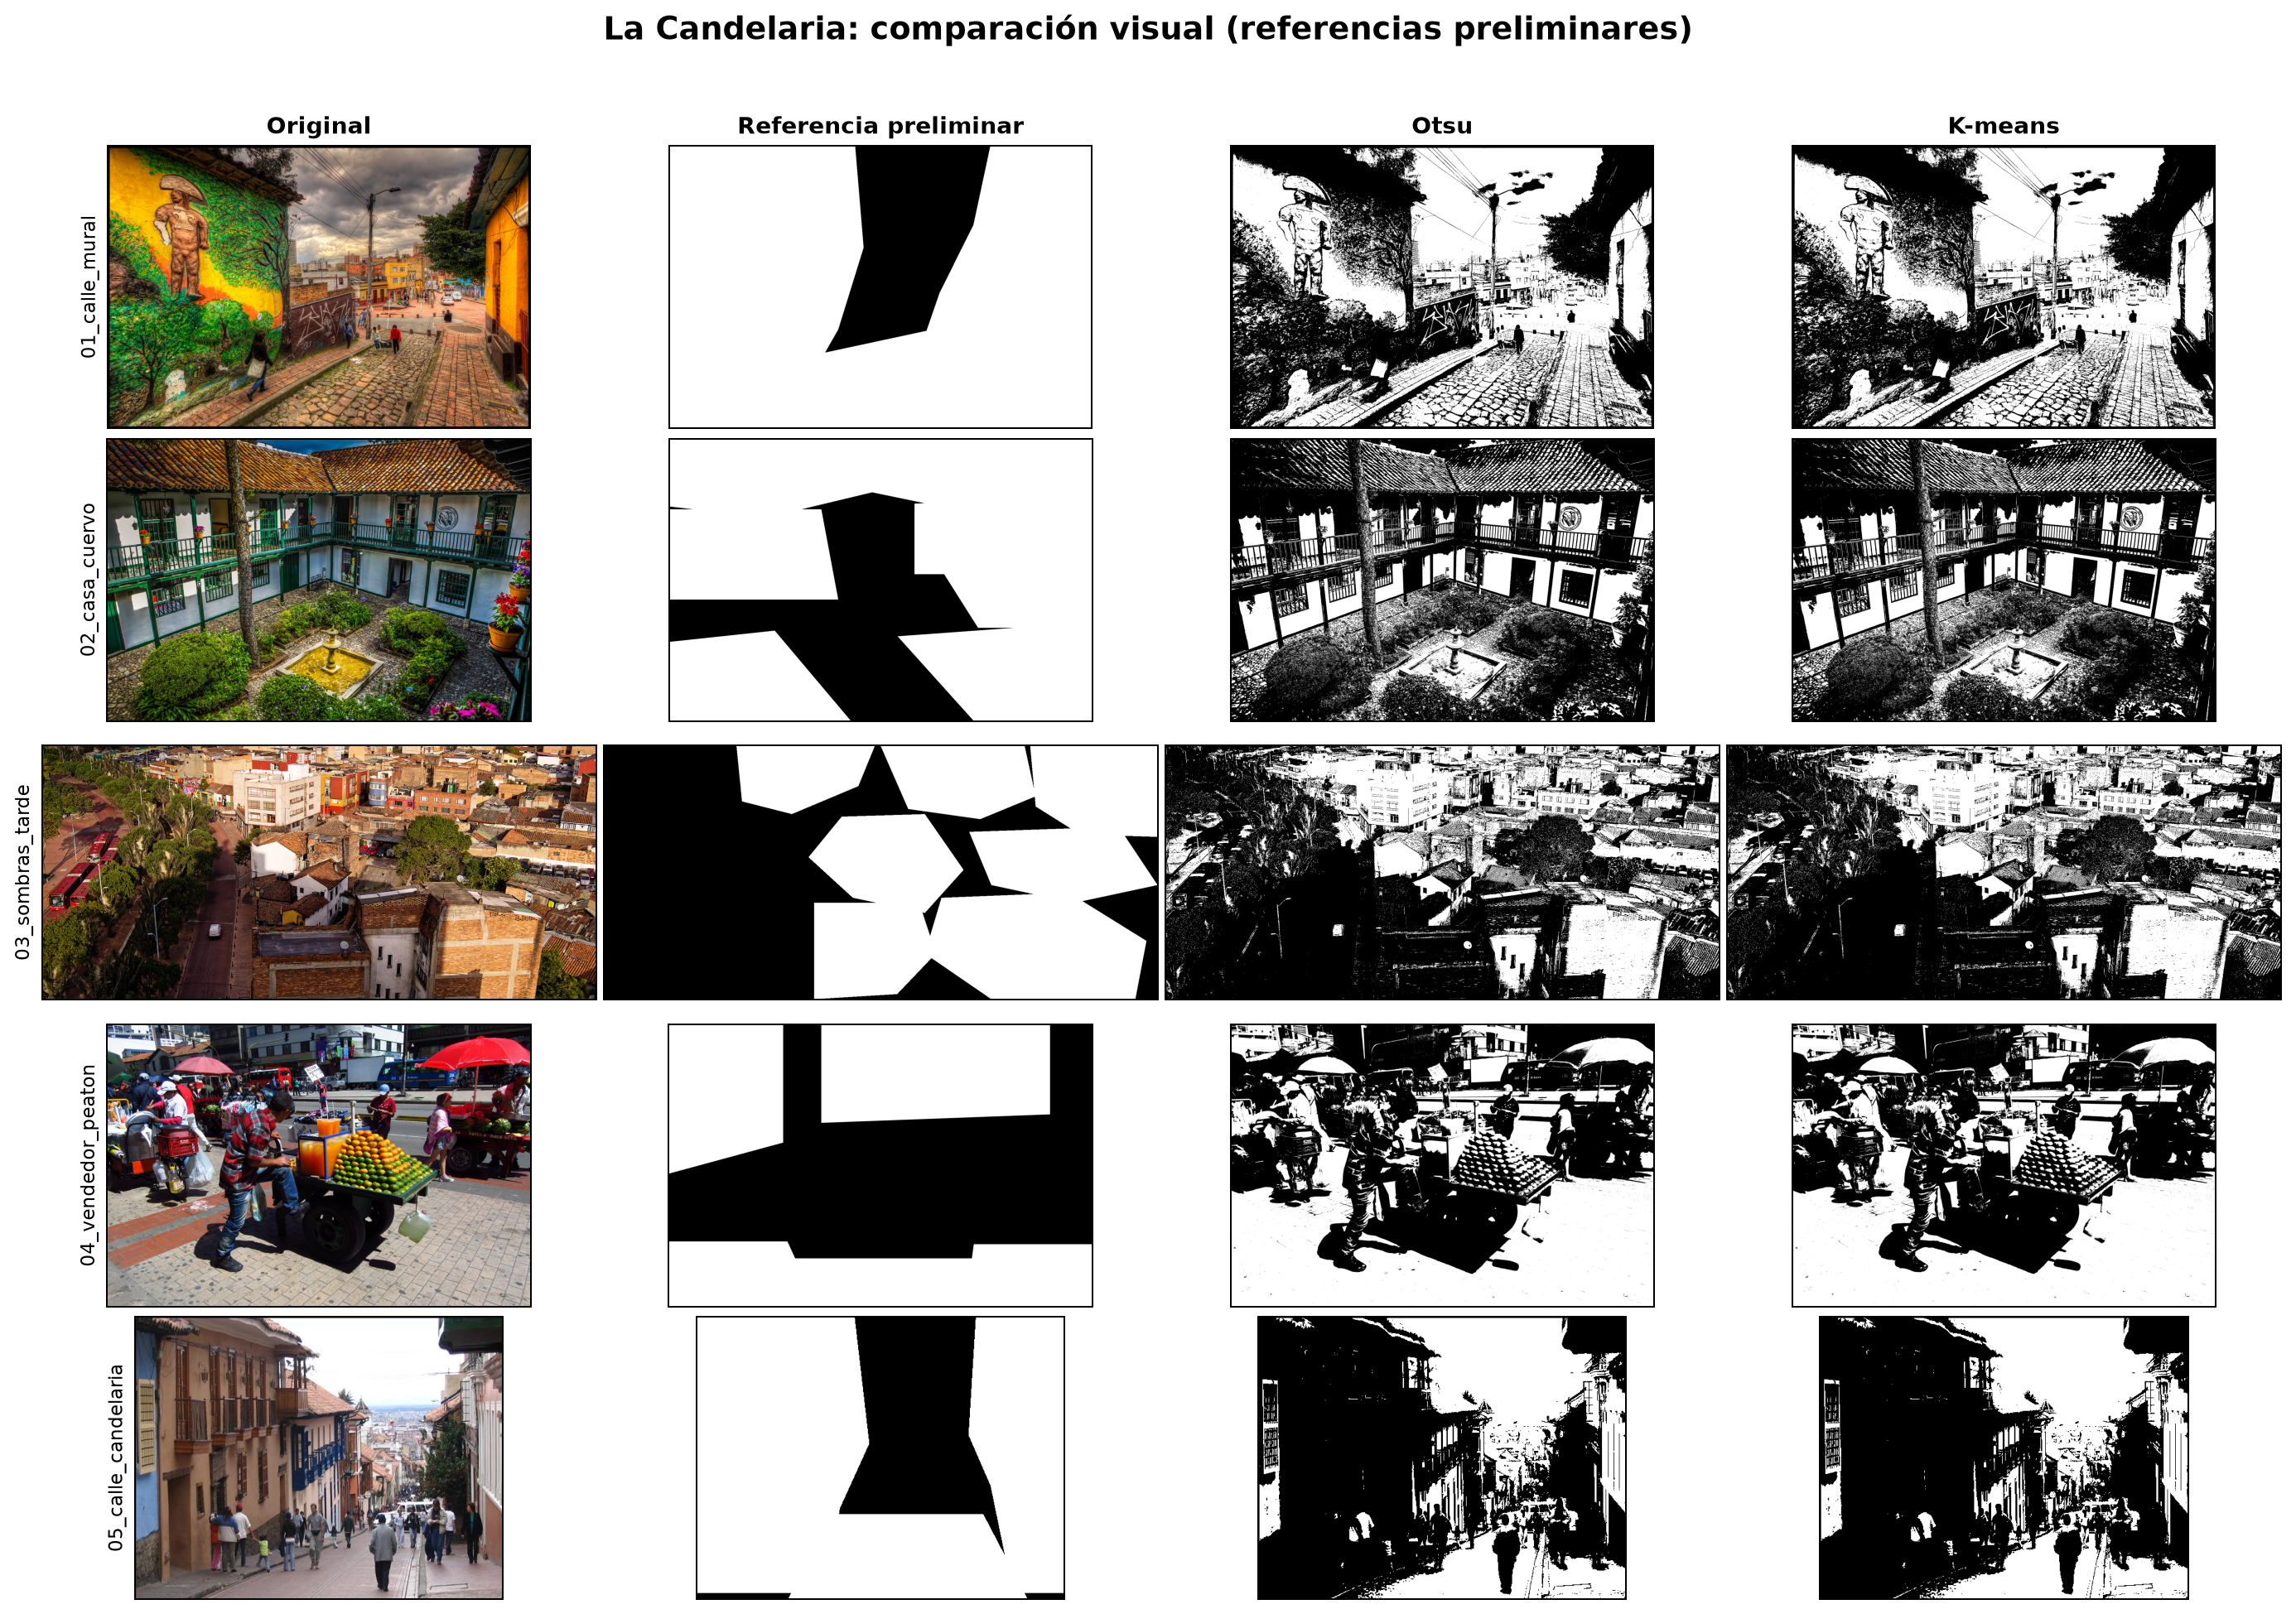

In [3]:
display(DisplayImage(filename=str(ROOT / case['overview_figure']), width=1050))

## Benchmark complementario: CrackForest Dataset

Se usan los IDs `001`, `024`, `050`, `074` y `116`, seleccionados mediante una regla determinista sin consultar predicciones ni métricas. La referencia procede de `groundTruth/<id>.mat`, campo `groundTruth.Segmentation`: etiqueta 2 = grieta/*foreground* y etiqueta 1 = pavimento intacto/*background*. Los archivos `.seg` se utilizan únicamente para comprobar integridad. Las cinco parejas superaron la inspección técnica de dimensiones, alineación y polaridad.

In [4]:
cfd = computed['complementary_benchmark']
show_metrics(cfd['rows'])
print('Matrices por imagen, orden [[TN, FP], [FN, TP]]:')
display(cfd['confusion_matrices'])
print('Agregado por píxel:')
display(cfd['aggregate_pixel_weighted'])

image,method,iou,dice,precision,recall,accuracy
001,Otsu,0.0266,0.0519,0.0267,0.8629,0.6239
001,K-means,0.0248,0.0484,0.0249,0.8689,0.5929
024,Otsu,0.0301,0.0584,0.0301,0.9269,0.3155
024,K-means,0.0299,0.0581,0.0300,0.9301,0.3101
050,Otsu,0.0169,0.0332,0.0169,0.8493,0.4814
050,K-means,0.0161,0.0317,0.0161,0.8610,0.4480
074,Otsu,0.0276,0.0537,0.0277,0.9007,0.5191
074,K-means,0.0258,0.0502,0.0258,0.9106,0.4784
116,Otsu,0.0178,0.0350,0.0179,0.9178,0.5035
116,K-means,0.0187,0.0367,0.0187,0.9105,0.5306


Matrices por imagen, orden [[TN, FP], [FN, TP]]:


{'001': {'Otsu': [[94256, 57513], [251, 1580]],
  'K-means': [[89486, 62283], [240, 1591]]},
 '024': {'Otsu': [[45198, 104885], [257, 3260]],
  'K-means': [[44368, 105715], [246, 3271]]},
 '050': {'Otsu': [[72572, 79416], [243, 1369]],
  'K-means': [[67423, 84565], [224, 1388]]},
 '074': {'Otsu': [[77634, 73640], [231, 2095]],
  'K-means': [[71362, 79912], [208, 2118]]},
 '116': {'Otsu': [[75954, 76137], [124, 1385]],
  'K-means': [[80123, 71968], [135, 1374]]}}

Agregado por píxel:


{'Otsu': {'metrics': {'iou': 0.024078869543174963,
   'dice': 0.047025420129830735,
   'precision': 0.02414523524720893,
   'recall': 0.897545159796202,
   'accuracy': 0.48867578125},
  'confusion_matrix': [[365614, 391591], [1106, 9689]]},
 'K-means': {'metrics': {'iou': 0.02346124391312934,
   'dice': 0.0458468633818062,
   'precision': 0.023520890423361543,
   'recall': 0.9024548402037981,
   'accuracy': 0.47201041666666665},
  'confusion_matrix': [[352762, 404443], [1053, 9742]]}}

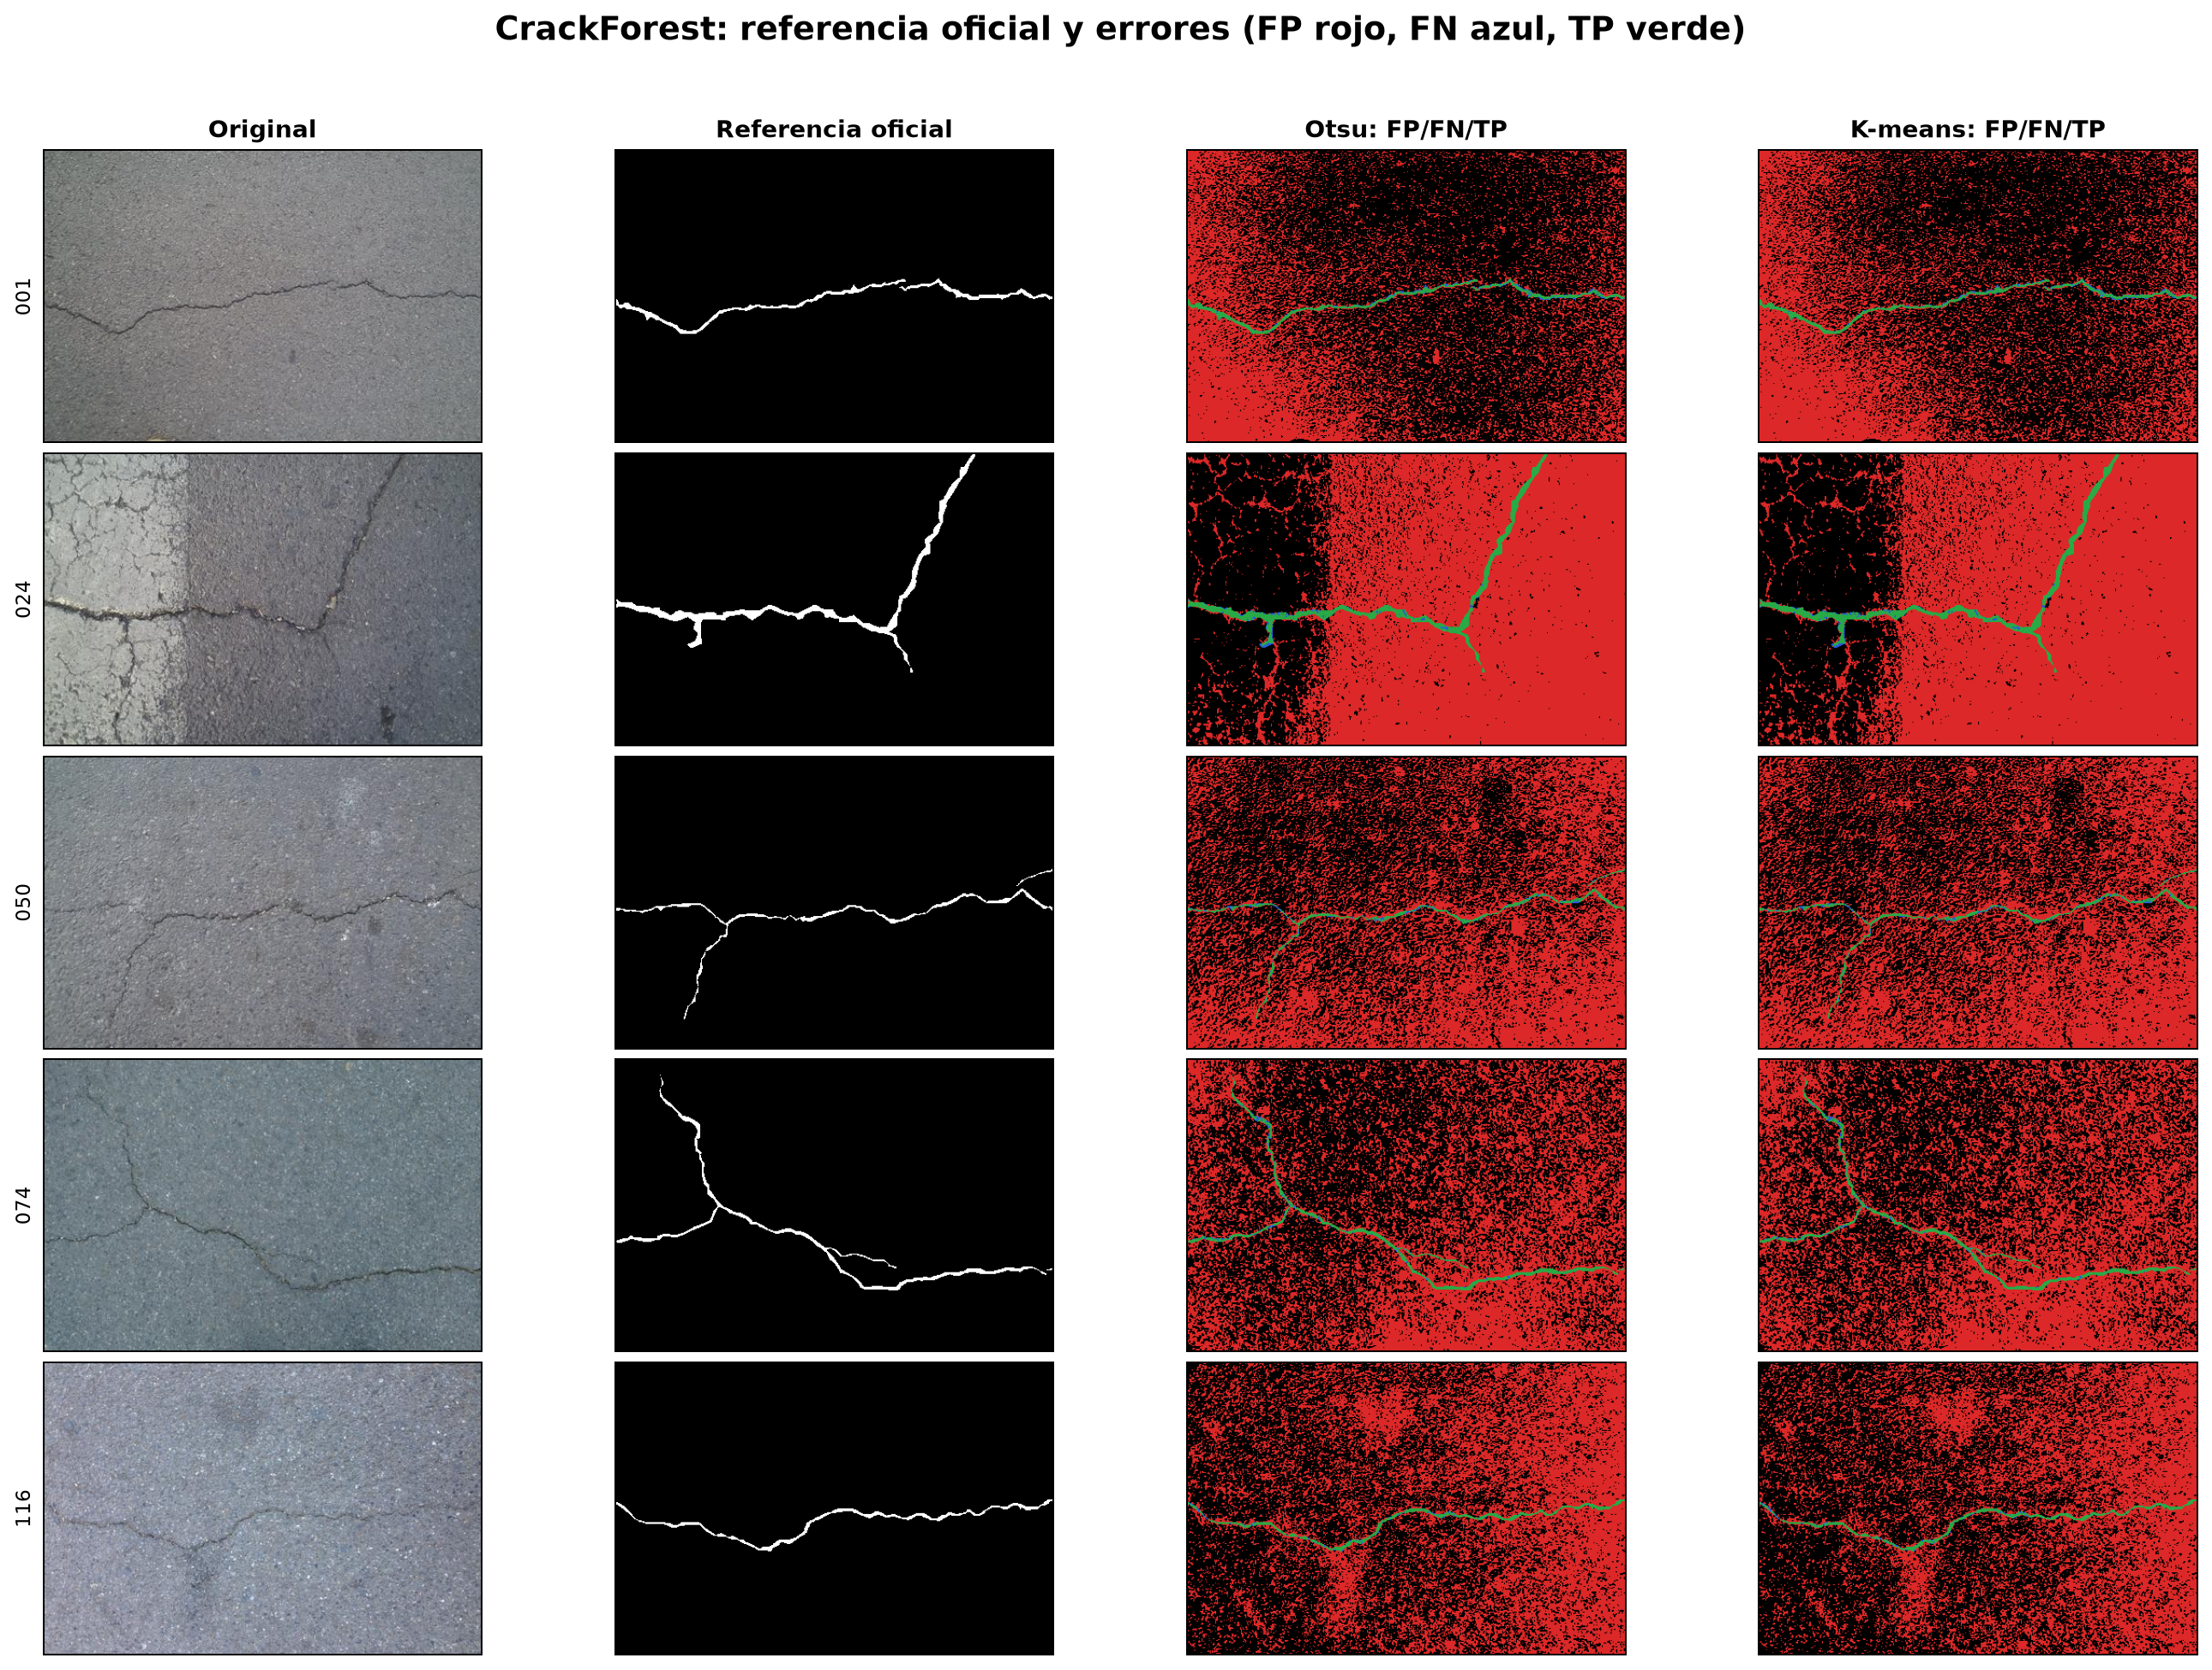

In [5]:
display(DisplayImage(filename=str(ROOT / cfd['overview_figure']), width=1050))

## Discusión conjunta

En La Candelaria, la similitud visual y numérica de Otsu y K-means se explica porque ambos reducen cada escena a una separación global de dos grupos sobre la misma intensidad media. Ese supuesto no representa una clase semántica urbana y las métricas dependen de referencias preliminares; solo describen el experimento.

En CFD, ambos métodos recuperan muchas grietas (recall alto), pero producen numerosos falsos positivos por textura, sombras y variaciones del pavimento. La baja precisión, IoU y Dice demuestra la limitación de la segmentación global por intensidad para estructuras finas y minoritarias.

La conclusión no es que los métodos sean equivalentes en general, sino que bajo este preprocesamiento fijo y estas muestras generan particiones muy próximas. QG1 permanece sin aprobar porque las referencias de La Candelaria no están visualmente validadas.

## Reproducibilidad y trazabilidad

El manifiesto `data/benchmarks/cfd5/manifest.json` registra repositorio, commit, licencia, hashes, etiquetas, regla de selección y verificaciones. Los datos crudos CFD no se publican en este repositorio; se regeneran desde el origen oficial para respetar su licencia de uso no comercial en investigación. Los resultados numéricos canónicos están en `deliverables/results.json`.